# Post-processing cost–benefit analysis

This notebook compares welfare in a reference PyPSA network with counterfactual networks where individual interconnectors, or the full bundle, are removed. The reproducible workflow is organised as: **load results → define metrics → build CBA tables → visualise benefits → calculate compensation**.

Cells labelled **Exploratory** are diagnostics or one-off investigations; they are not required for the main results and may rely on optional variables or external files.

## 1. Setup and input data

Run these cells first. The paths are intentionally kept in one place so the analysis can be moved to another results directory.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pypsa

# Update these two paths when using a different results directory.
RESULTS_DIR = Path("/Users/ng-work/Models/pypsa-monte_carlo/results/analysis_v0")
RESULTS_ALT_DIR = Path("/Users/ng-work/Models/pypsa-monte_carlo/results/analysis_v0_alt")


In [3]:
SCENARIOS = {
    "reference": "base",
    "nautilus": "no-Nautilus",
    "lionlink": "no-LionLink",
    "triton": "no-TritonLink",
    "de_gb_interconnector": "no-DE-GB_interconnector",
    "fr_gb_interconnector": "no-FR-GB_interconnector",
    "bundle": "bundle",
}

def load_welfare_results(results_dir: Path) -> dict[str, pd.DataFrame]:
    """Load welfare-by-country results for every configured scenario."""
    return {
        name: pd.read_csv(results_dir / folder / "welfare_by_country.csv")
        for name, folder in SCENARIOS.items()
    }

results = load_welfare_results(RESULTS_DIR)
results_alt = load_welfare_results(RESULTS_ALT_DIR)

# Named aliases keep the analysis cells readable.
reference = results["reference"]
cf_nautilus = results["nautilus"]
cf_lionlink = results["lionlink"]
cf_triton = results["triton"]
cf_icdegb = results["de_gb_interconnector"]
cf_icfrgb = results["fr_gb_interconnector"]
cf_bundle = results["bundle"]

reference_alt = results_alt["reference"]
cf_nautilus_alt = results_alt["nautilus"]
cf_lionlink_alt = results_alt["lionlink"]
cf_triton_alt = results_alt["triton"]
cf_icdegb_alt = results_alt["de_gb_interconnector"]
cf_icfrgb_alt = results_alt["fr_gb_interconnector"]
cf_bundle_alt = results_alt["bundle"]


## 3. Monte Carlo convergence

These cells estimate how the expected total welfare stabilises as more samples are included. The first plot is the recommended summary; the following distribution checks are exploratory.

In [4]:
import numpy as np
total_list = reference.groupby('sample').total.sum()
s = 1
mean = []
convergence = []
while s < len(total_list):
    convergence.append((np.std(total_list[:s])/np.sqrt(s+1)))
    deviation = (np.std(total_list[:s]))
    mean.append(np.mean(total_list[:s]))
    print((np.std(total_list[:s])/np.sqrt(s+1)))
    s += 1

0.0
8711116021.456007
65973474789.59423
106711656552.17047
92994151044.52919
80583611251.58807
78203348722.07245
69818657457.81401
63860130525.11154
69274665408.39153
63440604955.69189
60569584098.91816
56430031858.226295
66719182767.298485
62549851462.06656
58878513763.962845
55859056009.3206
56455185097.55627
57309378805.45753
56279651111.40726
54023860644.38946
51649455745.91727
49531612544.89259
47538270119.94538
45772211934.974174
44058291986.35352
42553779694.113144
42800620857.23605
41681008414.13301
40854887006.68531
39573456505.29674
40816481495.736786
39819114521.15369
38800673142.38248
37712677048.20954
36716738254.271545
36001935430.889534
35900053533.65444
35675957000.36033
34796599121.568756
34710610152.73923
34118891304.754997
33372612970.634537
33805901361.942173
33095465122.42525
32385082189.216255
31888991606.233772
32537069420.132225
32416763400.125557
32398931643.038624
31823979139.64944
31233853593.555546
31323038306.192345
30874454115.39741
30841496238.429836
3044

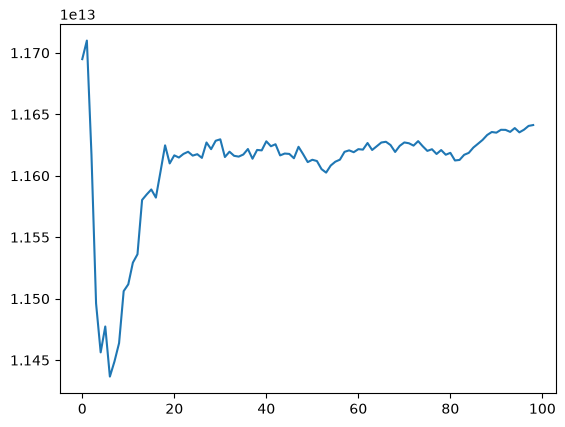

In [6]:
plt.plot(mean)

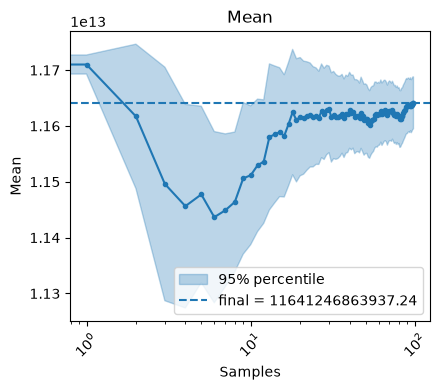

In [5]:
import numpy as np
import matplotlib.pyplot as plt

samples = np.asarray(np.arange(len(total_list)-1))
mean = np.asarray(mean)
std = np.asarray(convergence)*1.96

fig, ax = plt.subplots(figsize=(4.5, 4))

# Mean curve with markers
ax.plot(samples, mean, "-o", color="C0", markersize=3, lw=1.5)

# Shaded ±σ band
ax.fill_between(samples, mean - std, mean + std,
                color="C0", alpha=0.3,
                label="95% percentile" #r"$\pm\sigma_\mu$"
                )

# Dashed horizontal line at the final value
final = mean[-1]
ax.axhline(final, color="C0", ls="--", lw=1.5,
           label=f"final = {final:.2f}")

# Log x-axis, rotated tick labels
ax.set_xscale("log")
ax.tick_params(axis="x", rotation=45)

ax.set_xlabel("Samples")
ax.set_ylabel("Mean")
ax.set_title("Mean")
ax.legend(loc="lower right")

fig.tight_layout()
plt.show()

> **Exploratory — distribution/check.** Retained for inspecting the Monte Carlo estimate and uncertainty assumptions.

In [ ]:
total_list.mean()/1e12 #alternative seed

> **Exploratory — distribution/check.** Retained for inspecting the Monte Carlo estimate and uncertainty assumptions.

In [ ]:
total_list.mean()/1e12 #original seed

> **Exploratory — distribution/check.** Retained for inspecting the Monte Carlo estimate and uncertainty assumptions.

In [ ]:
((11.63818703596475 - 11.639363094449994)/11.639363094449994)*100

> **Exploratory — distribution/check.** Retained for inspecting the Monte Carlo estimate and uncertainty assumptions.

In [ ]:
(1.96 * 24065449872.3474/1e12)

> **Exploratory — distribution/check.** Retained for inspecting the Monte Carlo estimate and uncertainty assumptions.

In [ ]:
(1.96 * 23769428987.358624/1e12)

> **Exploratory — distribution/check.** Retained for inspecting the Monte Carlo estimate and uncertainty assumptions.

In [8]:
normal = np.random.normal(loc=total_list.mean(), scale=24065449872.3474, size=10000)

> **Exploratory — distribution/check.** Retained for inspecting the Monte Carlo estimate and uncertainty assumptions.

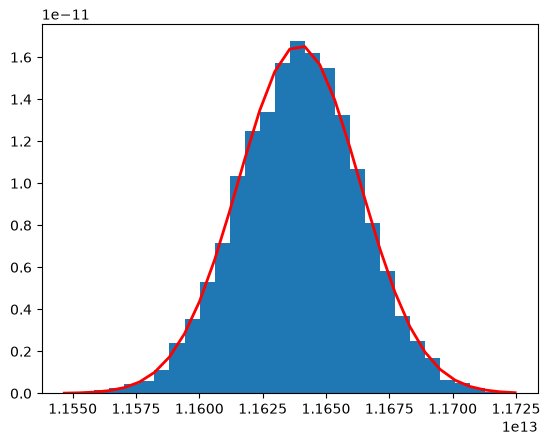

In [9]:
import matplotlib.pyplot as plt
count, bins, ignored = plt.hist(normal, 30, density=True)
plt.plot(bins, 1/(24065449872.3474 * np.sqrt(2 * np.pi)) *
               np.exp( - (bins - total_list.mean())**2 / (2 * 24065449872.3474**2) ),
         linewidth=2, color='r')
plt.show()

## 4. Welfare aggregation and CBA metrics

In [12]:
def welfare_by_country(network_welfare: pd.DataFrame, sample) -> pd.Series:
    """Aggregate total welfare by country for one Monte Carlo sample."""
    sample_data = network_welfare.query("sample == @sample")
    return sample_data.groupby("country")["total"].sum()


In [13]:
def cba(reference: pd.DataFrame, counterfactual: pd.DataFrame, sample) -> pd.Series:
    """Return the country-level welfare benefit of retaining a project."""
    return welfare_by_country(reference, sample).subtract(
        welfare_by_country(counterfactual, sample), fill_value=0
    )


## 7. Main CBA tables and visualisations

The next cells build reproducible country-level benefit tables for each counterfactual and for the alternative result set.


In [14]:
COUNTERFACTUALS = {
    "LionLink": cf_lionlink,
    "TritonLink": cf_triton,
    "DE-GB interconnector": cf_icdegb,
    "FR-GB interconnector": cf_icfrgb,
    "Nautilus": cf_nautilus,
    "Bundle": cf_bundle,
}


def build_cba_table(reference_data: pd.DataFrame, counterfactual_data: dict[str, pd.DataFrame]) -> pd.DataFrame:
    """Build one row per counterfactual, sample, and country."""
    rows = []
    for name, counterfactual in counterfactual_data.items():
        for sample in reference_data["sample"].unique():
            for country, benefit in cba(reference_data, counterfactual, sample).items():
                rows.append({
                    "counterfactual": name,
                    "sample": sample,
                    "country": country,
                    "effect": benefit,
                })

    table = pd.DataFrame(rows)
    individual = table[table["counterfactual"] != "Bundle"]
    summed = (
        individual.groupby(["sample", "country"], as_index=False)["effect"]
        .sum()
        .assign(counterfactual="Sum of projects")
    )
    return pd.concat([table, summed], ignore_index=True)


df = build_cba_table(reference, COUNTERFACTUALS)


In [18]:
COUNTERFACTUALS_ALT = {
    "LionLink": cf_lionlink_alt,
    "TritonLink": cf_triton_alt,
    "DE-GB interconnector": cf_icdegb_alt,
    "FR-GB interconnector": cf_icfrgb_alt,
    "Nautilus": cf_nautilus_alt,
    "Bundle": cf_bundle_alt,
}

df_alt = build_cba_table(reference_alt, COUNTERFACTUALS_ALT)


> **Exploratory — plot/statistic variant.**

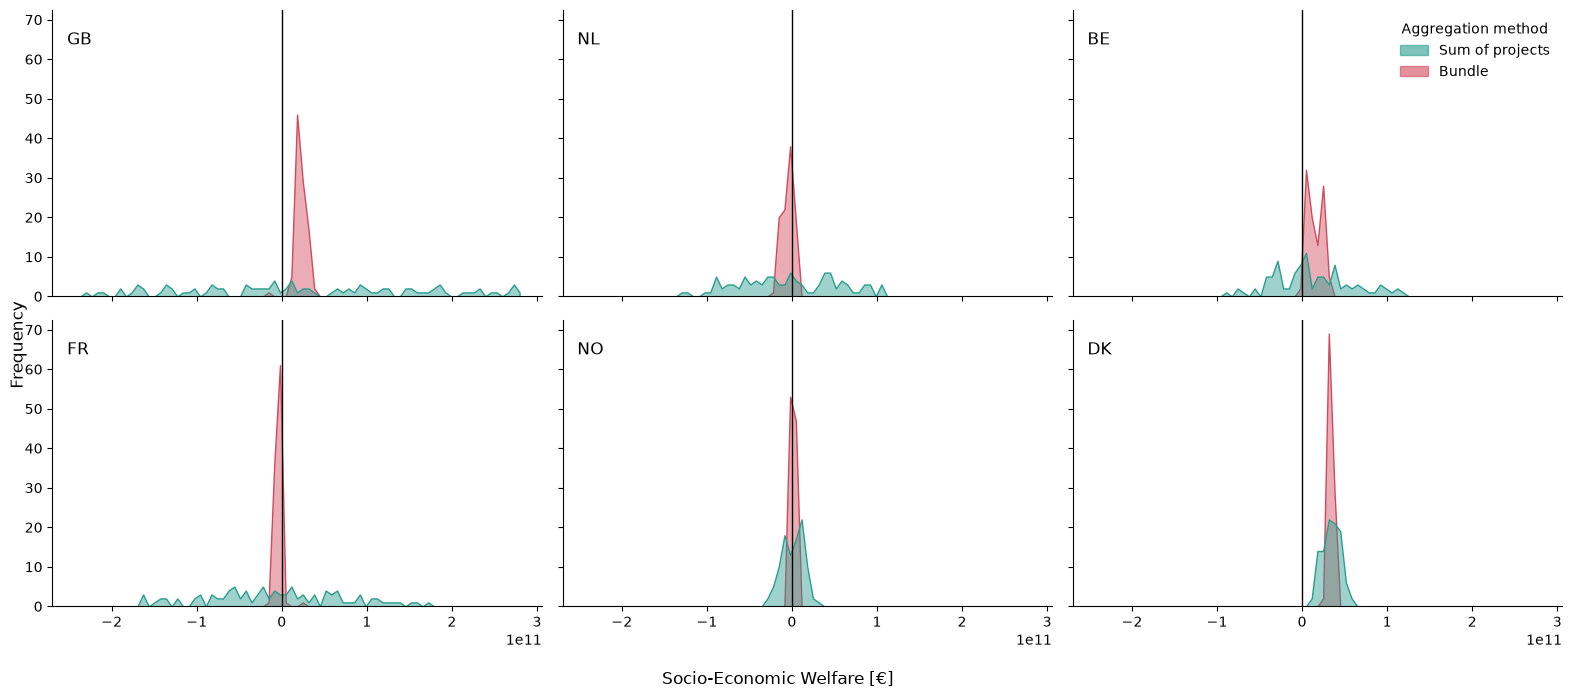

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

countries = ["GB", "NL", "BE", "FR", "NO", "DK"]
hue_order = ["Sum of projects", "Bundle"]
palette = {"Sum of projects": "#2a9d8f", "Bundle": "#d1495b"}

d = df[df.country.isin(countries)]

# Common bins across all panels so the shapes are comparable
bins = np.linspace(d["effect"].min(), d["effect"].max(), 80)

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 7),
    sharex=True, sharey=True,
)

for ax, country in zip(axes.flat, countries):
    sub = d[d.country == country]

    sns.histplot(
        data=sub,
        x="effect",
        hue="counterfactual",
        hue_order=hue_order,
        palette=palette,
        bins=bins,
        element="poly",
        fill=True,
        alpha=0.45,
        linewidth=1,
        legend=False,
        ax=ax,
    )

    # sns.kdeplot(
    #     data=sub,
    #     x="effect",
    #     hue="counterfactual",
    #     hue_order=hue_order,
    #     palette=palette,
    #     fill=True,
    #     alpha=0.45,
    #     common_norm=False,
    #     legend=False,
    #     ax=ax,
    # )

    ax.axvline(0, color="black", lw=1)
    ax.text(0.03, 0.88, country, transform=ax.transAxes, fontsize=12)
    ax.set_xlabel("")
    ax.set_ylabel("")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

# Shared labels
fig.supxlabel("Socio-Economic Welfare [€]")
fig.supylabel("Frequency")

# Single legend, placed in the first panel
handles = [plt.Rectangle((0, 0), 1, 1, color=palette[h], alpha=0.6) for h in hue_order]
axes[0, -1].legend(handles, hue_order, title="Aggregation method",
                   loc="upper right", frameon=False)

plt.tight_layout()
plt.show()

> **Exploratory — plot/statistic variant.**

In [19]:
import pandas as pd

countries = ["GB", "NL", "BE", "FR", "NO", "DK"]
scenarios = ["Sum of projects", "Bundle"]

def summarize(d, suffix=""):
    return (
        d[d.country.isin(countries) & d.counterfactual.isin(scenarios)]
        .groupby(["country", "counterfactual"])["effect"]
        .agg(expected="mean", std="std")
        .add_suffix(suffix)
    )

table = summarize(df).join(summarize(df_alt, "_alt"))

table["expected_rel_diff"] = (table.expected - table.expected_alt) / table.expected
table["std_rel_diff"] = (table["std"] - table.std_alt) / table["std"]

print(table)

                             expected           std  expected_alt  \
country counterfactual                                              
BE      Bundle           1.455776e+10  9.198267e+09  1.403223e+10   
        Sum of projects  1.292967e+10  4.614622e+10  1.271152e+10   
DK      Bundle           3.360087e+10  2.642552e+09  3.374665e+10   
        Sum of projects  3.409177e+10  1.082155e+10  3.413376e+10   
FR      Bundle          -4.469276e+09  3.918176e+09 -3.645169e+09   
        Sum of projects -6.699240e+09  7.952286e+10 -3.903083e+09   
GB      Bundle           2.205931e+10  6.434345e+09  2.190250e+10   
        Sum of projects  2.801516e+10  1.357615e+11  2.438568e+10   
NL      Bundle          -5.214402e+09  6.592507e+09 -4.562733e+09   
        Sum of projects -4.541392e+09  5.801486e+10 -5.538869e+09   
NO      Bundle           1.504803e+09  1.405893e+09  1.383586e+09   
        Sum of projects  9.356770e+08  1.280195e+10  1.195428e+09   

                              std